In [1]:
import pandas as pd
import matplotlib as plt
import seaborn as sns
import numpy as np
import datetime as dt

import plotly
import plotly.express as px
import plotly.graph_objects as go
import cufflinks as cf


In [2]:
df_test=pd.read_csv('DailyDelhiClimateTest.csv',parse_dates=['date'], index_col="date")

df_train=pd.read_csv('DailyDelhiClimateTrain.csv',parse_dates=['date'], index_col="date")

In [3]:
df_train.head()

,meantemp,humidity,wind_speed,meanpressure
date,,,,
2013-01-01,10.000000,84.500000,0.000000,1015.666667
2013-01-02,7.400000,92.000000,2.980000,1017.800000
2013-01-03,7.166667,87.000000,4.633333,1018.666667
2013-01-04,8.666667,71.333333,1.233333,1017.166667
2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [4]:
df_test.head()

,meantemp,humidity,wind_speed,meanpressure
date,,,,
2017-01-01,15.913043,85.869565,2.743478,59.000000
2017-01-02,18.500000,77.222222,2.894444,1018.277778
2017-01-03,17.111111,81.888889,4.016667,1018.333333
2017-01-04,18.700000,70.050000,4.545000,1015.700000
2017-01-05,18.388889,74.944444,3.300000,1014.333333


In [5]:
df_train.info()
df_test.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1462 entries, 2013-01-01 to 2017-01-01
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   meantemp      1462 non-null   float64
 1   humidity      1462 non-null   float64
 2   wind_speed    1462 non-null   float64
 3   meanpressure  1462 non-null   float64
dtypes: float64(4)
memory usage: 57.1 KB
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 114 entries, 2017-01-01 to 2017-04-24
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   meantemp      114 non-null    float64
 1   humidity      114 non-null    float64
 2   wind_speed    114 non-null    float64
 3   meanpressure  114 non-null    float64
dtypes: float64(4)
memory usage: 4.5 KB


In [6]:
train_shape=df_train.shape
test_shape= df_test.shape
print("shape of train is: ",train_shape)
print("shape of test is: ",test_shape)

shape of train is:  (1462, 4)
shape of test is:  (114, 4)


In [7]:
df_train.describe()

,meantemp,humidity,wind_speed,meanpressure
count,1462.000000,1462.000000,1462.000000,1462.000000
mean,25.495521,60.771702,6.802209,1011.104548
std,7.348103,16.769652,4.561602,180.231668
min,6.000000,13.428571,0.000000,-3.041667
25%,18.857143,50.375000,3.475000,1001.580357
50%,27.714286,62.625000,6.221667,1008.563492
75%,31.305804,72.218750,9.238235,1014.944901
max,38.714286,100.000000,42.220000,7679.333333


In [8]:
df_test.describe()

,meantemp,humidity,wind_speed,meanpressure
count,114.000000,114.000000,114.000000,114.000000
mean,21.713079,56.258362,8.143924,1004.035090
std,6.360072,19.068083,3.588049,89.474692
min,11.000000,17.750000,1.387500,59.000000
25%,16.437198,39.625000,5.563542,1007.437500
50%,19.875000,57.750000,8.069444,1012.739316
75%,27.705357,71.902778,10.068750,1016.739583
max,34.500000,95.833333,19.314286,1022.809524


In [9]:



# Concatenate your data for EDA and feature engineering
full_df = pd.concat([df_test, df_train])


full_df
full_df.info()

# Split your data back into train and test datasets
#train_df, test_df = full_df.split(test_size=0.2, random_state=42)

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1576 entries, 2017-01-01 to 2017-01-01
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   meantemp      1576 non-null   float64
 1   humidity      1576 non-null   float64
 2   wind_speed    1576 non-null   float64
 3   meanpressure  1576 non-null   float64
dtypes: float64(4)
memory usage: 61.6 KB


In [10]:
full_df.isnull().sum()

meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64

In [11]:
full_df

,meantemp,humidity,wind_speed,meanpressure
date,,,,
2017-01-01,15.913043,85.869565,2.743478,59.000000
2017-01-02,18.500000,77.222222,2.894444,1018.277778
2017-01-03,17.111111,81.888889,4.016667,1018.333333
2017-01-04,18.700000,70.050000,4.545000,1015.700000
2017-01-05,18.388889,74.944444,3.300000,1014.333333
...,...,...,...,...
2016-12-28,17.217391,68.043478,3.547826,1015.565217
2016-12-29,15.238095,87.857143,6.000000,1016.904762
2016-12-30,14.095238,89.666667,6.266667,1017.904762


In [12]:
# creating new features for EDA

full_df["year"] = full_df.index.year
full_df['month'] = full_df.index.month 
full_df['day'] = full_df.index.day
full_df['dayofweek'] = full_df.index.dayofweek
full_df["date"] = full_df.index.date

full_df.sample()

,meantemp,humidity,wind_speed,meanpressure,year,month,day,dayofweek,date
date,,,,,,,,,
2016-07-28,29.533333,81.333333,5.186667,1002.066667,2016,7,28,3,2016-07-28


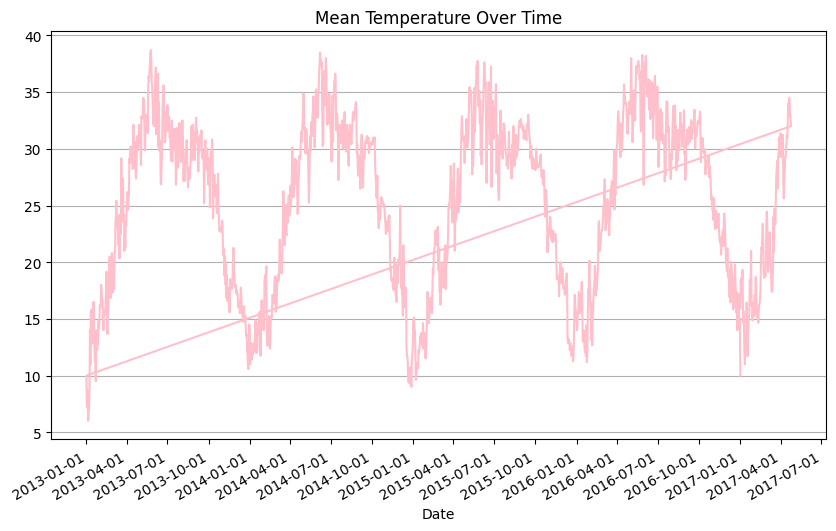

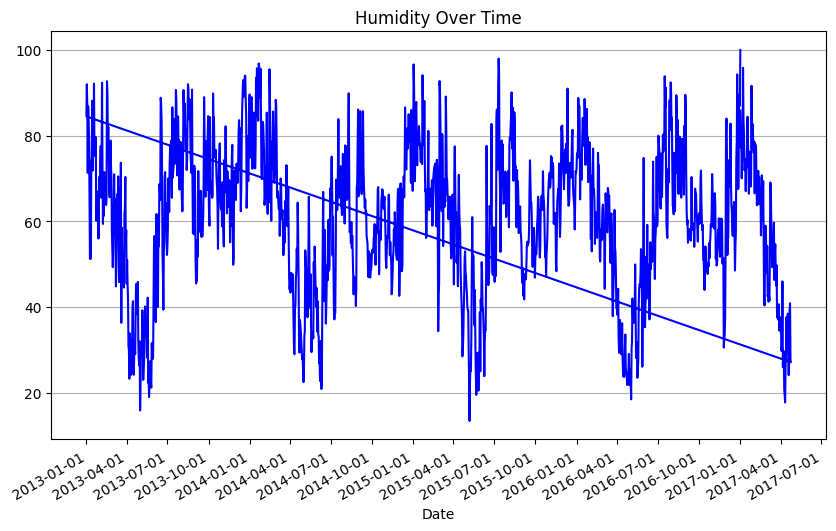

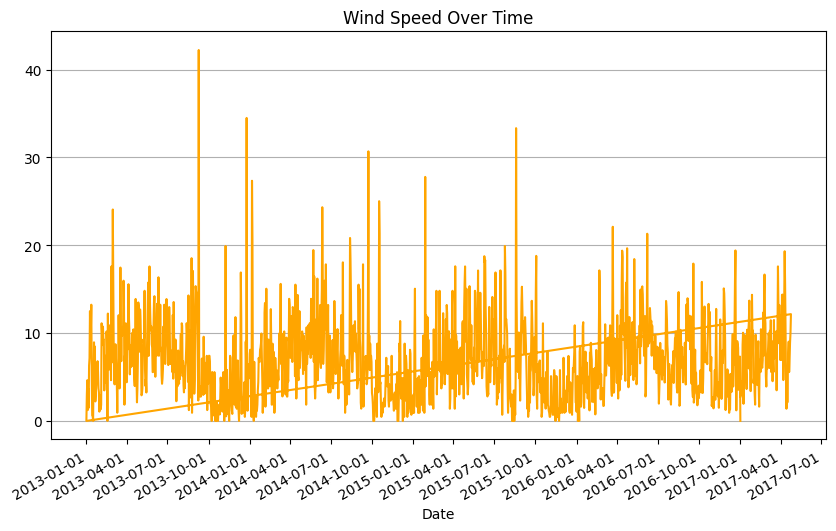

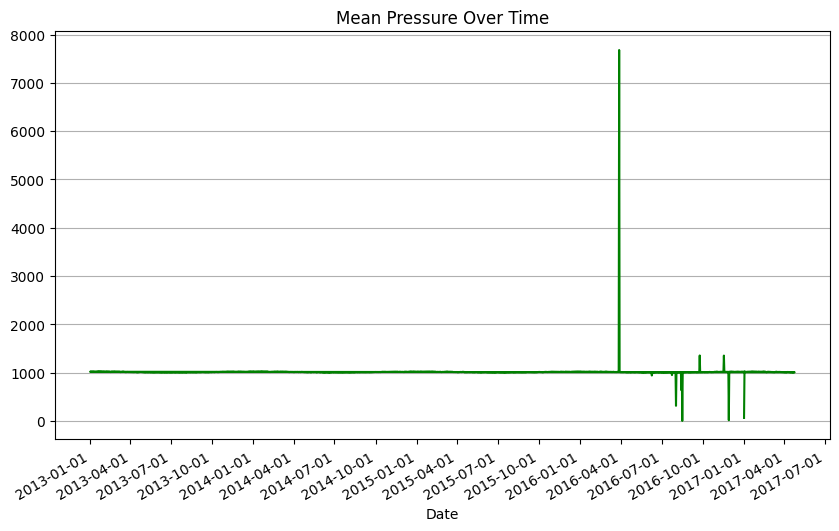

In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Line Plots
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(full_df.index, full_df['meantemp'],color='pink')
ax.set_title('Mean Temperature Over Time')
ax.set_xlabel("Date")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)) # Show every 3rd month
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
fig.autofmt_xdate()  # This will make the x-axis dates slant so they don't overlap
plt.grid(axis='y')  # Only show horizontal grids
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(full_df.index, full_df['humidity'],color='blue')
ax.set_title('Humidity Over Time')
ax.set_xlabel("Date")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))  # Show every 3rd month
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
fig.autofmt_xdate()  
plt.grid(axis='y')  # Only show horizontal grids
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(full_df.index, full_df['wind_speed'],color='orange')
ax.set_title('Wind Speed Over Time')
ax.set_xlabel("Date")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3)) # Show every 3rd month
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
fig.autofmt_xdate()  
plt.grid(axis='y')  
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(full_df.index, full_df['meanpressure'],color='green')
ax.set_title('Mean Pressure Over Time')
ax.set_xlabel("Date")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))  # Show every 3rd month so that the texts dont overlap
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d'))
fig.autofmt_xdate() 
plt.grid(axis='y')  
plt.show()

In [ ]:
df_train.info()
df_test.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1462 entries, 2013-01-01 to 2017-01-01
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   meantemp      1462 non-null   float64
 1   humidity      1462 non-null   float64
 2   wind_speed    1462 non-null   float64
 3   meanpressure  1462 non-null   float64
dtypes: float64(4)
memory usage: 57.1 KB
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 114 entries, 2017-01-01 to 2017-04-24
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   meantemp      114 non-null    float64
 1   humidity      114 non-null    float64
 2   wind_speed    114 non-null    float64
 3   meanpressure  114 non-null    float64
dtypes: float64(4)
memory usage: 4.5 KB


In [16]:
from statsmodels.tsa.seasonal import seasonal_decompose
import plotly.subplots as sp

# Perform seasonal decomposition
result = seasonal_decompose(full_df['meantemp'], model='additive', period=365)

# Plot the decomposed components
fig = sp.make_subplots(rows=4, cols=1, shared_xaxes=True, 
                       subplot_titles=['Observed', 'Trend', 'Seasonal', 'Residual'])

fig.add_trace(go.Scatter(x=full_df.index, y=result.observed, mode='lines', name='Observed'), row=1, col=1)
fig.add_trace(go.Scatter(x=full_df.index, y=result.trend, mode='lines', name='Trend'), row=2, col=1)
fig.add_trace(go.Scatter(x=full_df.index, y=result.seasonal, mode='lines', name='Seasonal'), row=3, col=1)
fig.add_trace(go.Scatter(x=full_df.index, y=result.resid, mode='lines', name='Residual'), row=4, col=1)


fig.show()

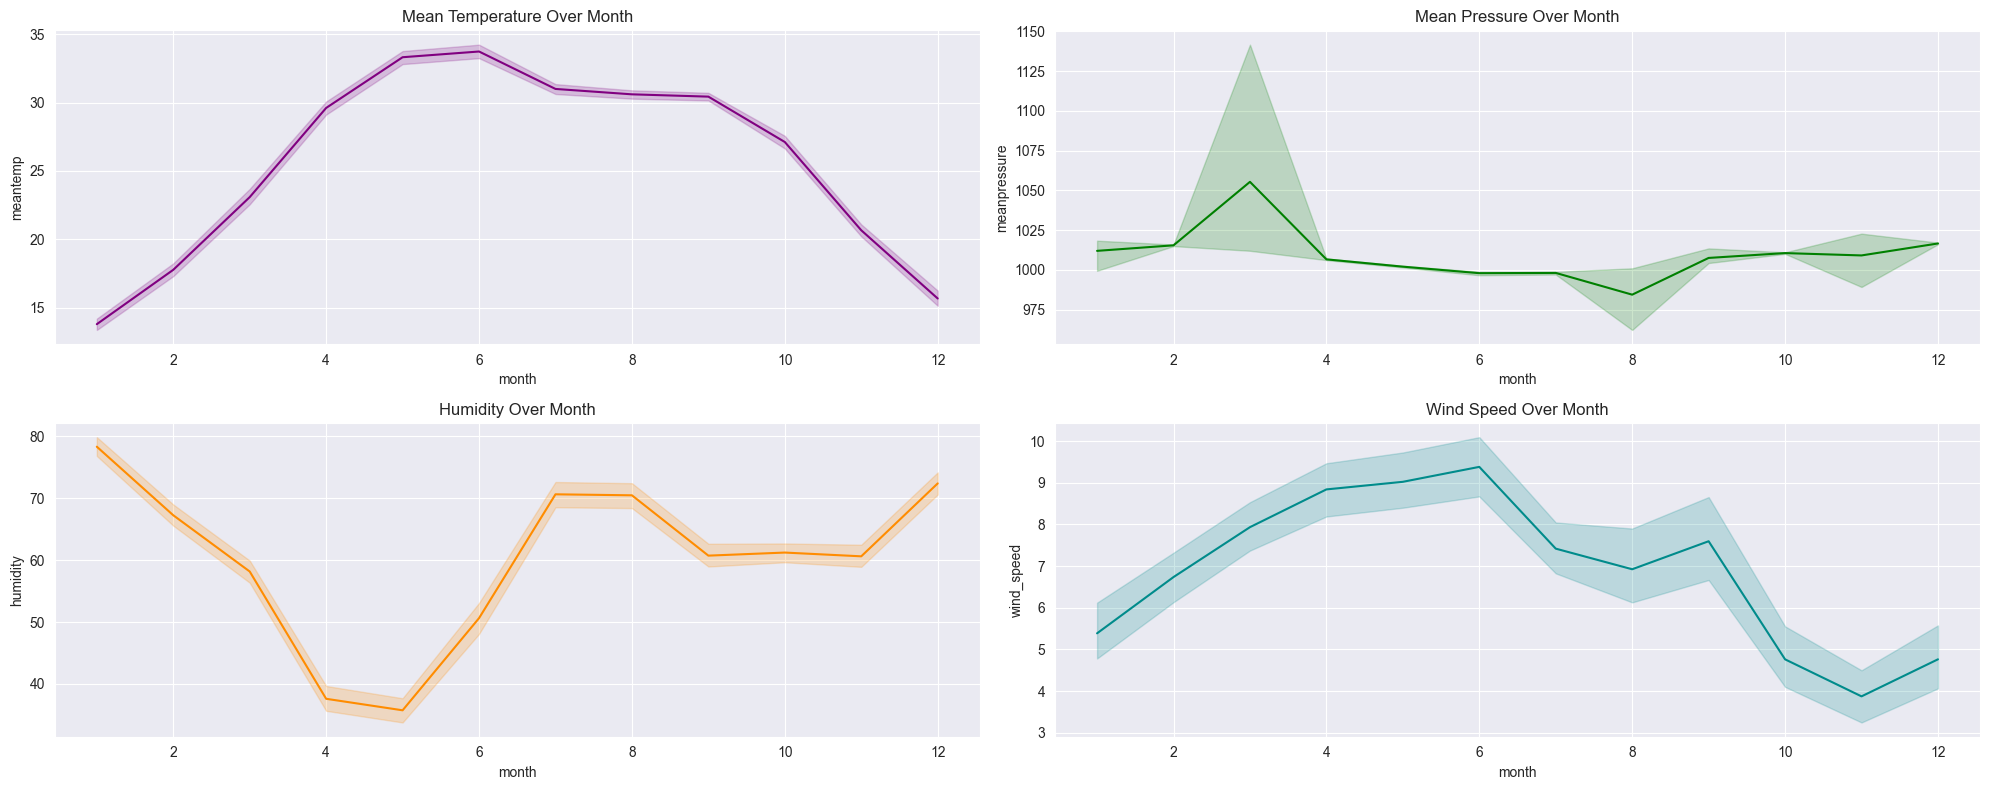

In [18]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 8))



# Plot each parameter against the 'month'
sns.lineplot(x='month', y='meantemp', data=full_df, color='purple', ax=axes[0][0])
axes[0][0].set_title('Mean Temperature Over Month')

sns.lineplot(x='month', y='humidity', data=full_df, color='darkorange', ax=axes[1][0])
axes[1][0].set_title('Humidity Over Month')

sns.lineplot(x='month', y='meanpressure', data=full_df, color='green', ax=axes[0][1])
axes[0][1].set_title('Mean Pressure Over Month')

sns.lineplot(x='month', y='wind_speed', data=full_df, color='darkcyan', ax=axes[1][1])
axes[1][1].set_title('Wind Speed Over Month')

plt.tight_layout()
plt.show()


correlation and heat maps 

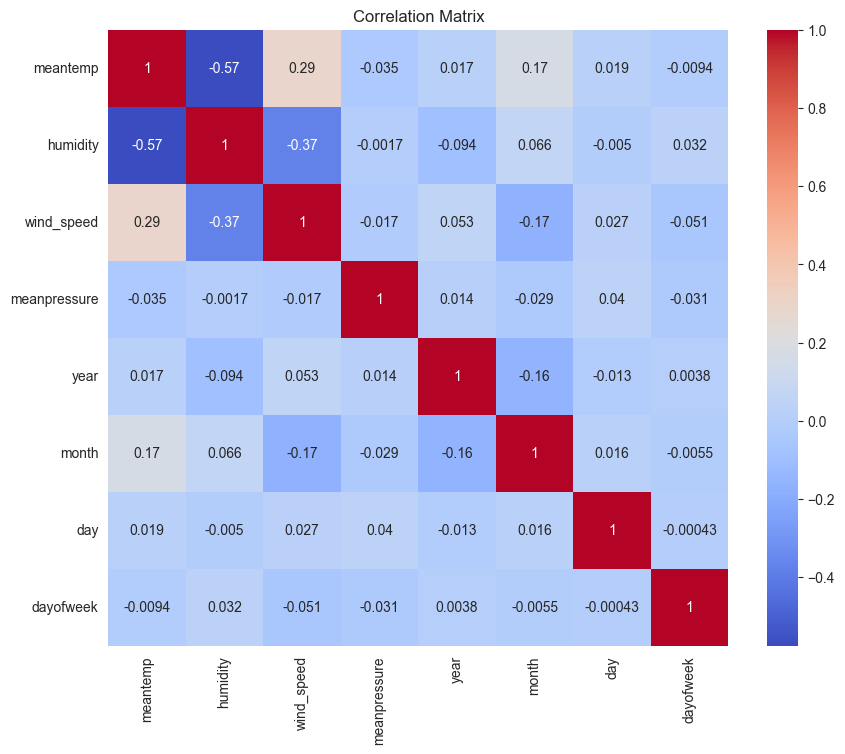

In [ ]:
numerical_df = full_df.select_dtypes(include=[np.number])

# Let's create the correlation matrix
correlation_matrix = numerical_df.corr()

# Let's visualize the correlation matrix
plt.figure(figsize=(10,8))
sns.heatmap(correlation_matrix, cmap='coolwarm', annot=True)
plt.title('Correlation Matrix')
plt.show()

histograms with seaborn

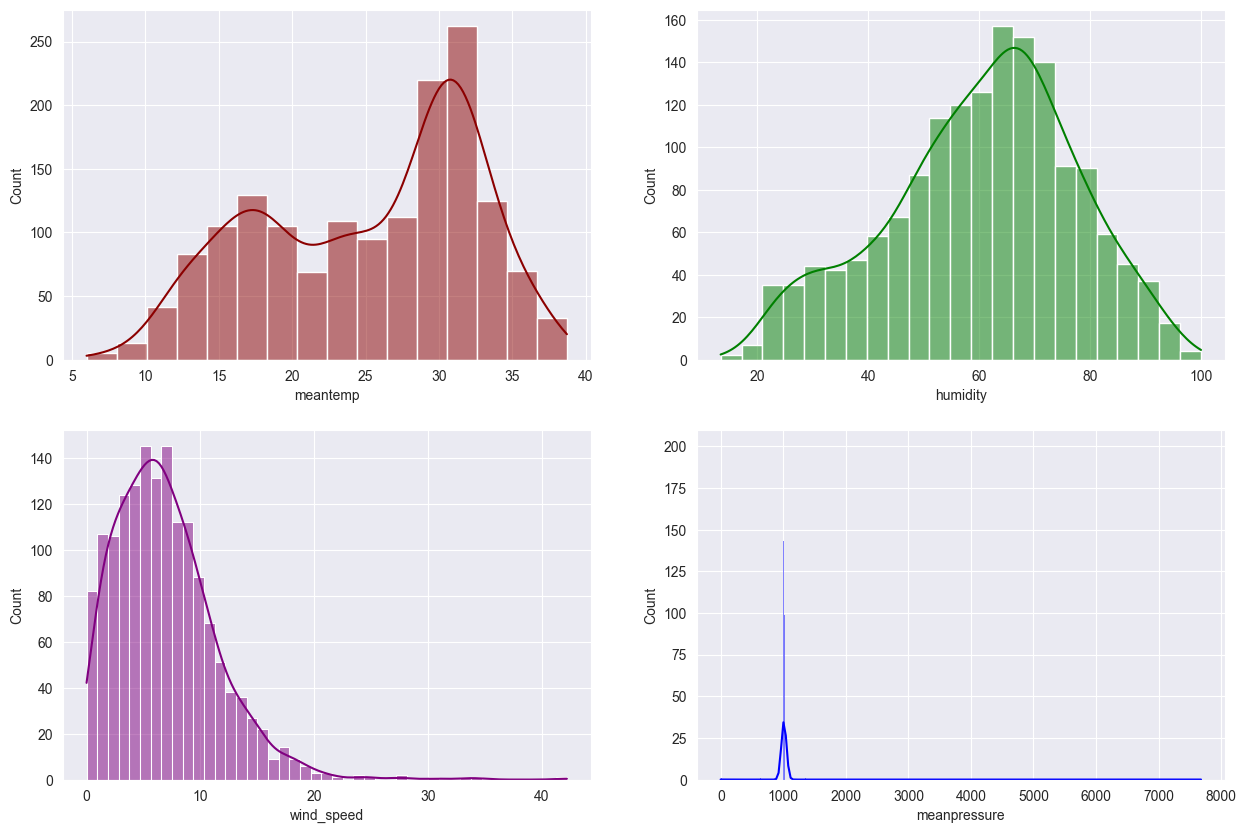

In [27]:
# Create subplots
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# Plot histograms with KDE
sns.histplot(data=full_df, x="meantemp", ax=ax[0][0], kde=True,color='darkred')
sns.histplot(data=full_df, x="humidity", ax=ax[0][1], kde=True, color='green')

sns.histplot(data=full_df, x="wind_speed", ax=ax[1][0], kde=True, color='purple')

sns.histplot(data=full_df, x="meanpressure", ax=ax[1][1], kde=True, color='blue')

# Show the plot
plt.show()


feature selection

In [28]:
df = full_df[['meantemp', 'humidity', 'wind_speed']]
df.head()

,meantemp,humidity,wind_speed
date,,,
2017-01-01,15.913043,85.869565,2.743478
2017-01-02,18.500000,77.222222,2.894444
2017-01-03,17.111111,81.888889,4.016667
2017-01-04,18.700000,70.050000,4.545000
2017-01-05,18.388889,74.944444,3.300000


In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1576 entries, 2017-01-01 to 2017-01-01
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   meantemp    1576 non-null   float64
 1   humidity    1576 non-null   float64
 2   wind_speed  1576 non-null   float64
dtypes: float64(3)
memory usage: 49.2 KB


train test split 

In [30]:
len(df)


1576

In [50]:
test_size =int(0.2*(len(df))) 

In [51]:
test_index = len(df)- test_size
test_index

1261

In [52]:
train = df.iloc[:test_index]
test = df.iloc[test_index:]

In [53]:
len(train)

1261

In [54]:
len(test)

315

In [55]:
train

,meantemp,humidity,wind_speed
date,,,
2017-01-01,15.913043,85.869565,2.743478
2017-01-02,18.500000,77.222222,2.894444
2017-01-03,17.111111,81.888889,4.016667
2017-01-04,18.700000,70.050000,4.545000
2017-01-05,18.388889,74.944444,3.300000
...,...,...,...
2016-02-17,18.714286,59.285714,3.707143
2016-02-18,19.466667,76.000000,5.186667
2016-02-19,23.153846,70.230769,4.146154


In [56]:
test

,meantemp,humidity,wind_speed
date,,,
2016-02-22,21.000000,51.428571,15.207143
2016-02-23,21.428571,50.642857,9.785714
2016-02-24,21.687500,58.062500,2.443750
2016-02-25,22.562500,57.500000,5.337500
2016-02-26,22.800000,55.600000,2.480000
...,...,...,...
2016-12-28,17.217391,68.043478,3.547826
2016-12-29,15.238095,87.857143,6.000000
2016-12-30,14.095238,89.666667,6.266667


scaling 

In [62]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train)
test_scaled = scaler.transform(test)

In [65]:
# Parameters
length = 12  # طول توالی های خروجی
batch_size = 1  #  the number of time series samples in each batch.
stride = 1  # طول هر قدم بین توالی های خروجی متوالی


data_2 = []
targets = []

for i in range(0, len(train_scaled) - length + 1, stride):
    data_2.append(train_scaled[i:i+length])
    targets.append(train_scaled[i+length-1])

data_2 = np.array(data_2)
targets = np.array(targets)

In [68]:
train_scaled.shape

(1261, 3)

In [66]:

test_scaled.shape

(315, 3)

In [67]:
n_features = train_scaled.shape[1]
n_features

3

modeling 

RNN

In [43]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, SimpleRNN, Bidirectional, Dropout

In [44]:
from keras.layers import Dropout

model = Sequential()
model.add(SimpleRNN(units=128, activation="tanh", input_shape=(length, n_features)))
model.add(Dropout(0.2))  # Dropout layer added, dropout rate set to 0.2
model.add(Dense(64, activation="tanh"))  # "relu" was used as activation function
model.add(Dropout(0.2))
model.add(Dense(32, activation="tanh"))  # "tanh" was used as activation function
model.add(Dropout(0.2))
model.add(Dense(1))

model.compile(optimizer="adam", loss="mse")

c:\Users\Shirin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [45]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,265 (106.50 KB)

 Trainable params: 27,265 (106.50 KB)

 Non-trainable params: 0 (0.00 B)

In [105]:
#training
from tensorflow.keras.callbacks import EarlyStopping
model.fit(data_2, targets, epochs = 30, batch_size=1)
loss = model.evaluate(data_2, targets)
print(f'Validation Loss: {loss}')

Epoch 1/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0658
Epoch 2/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0657
Epoch 3/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0661
Epoch 4/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0656
Epoch 5/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0644
Epoch 6/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0663
Epoch 7/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0657
Epoch 8/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0661
Epoch 9/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0655
Epoch 10/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0662
Epoch 11/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0644
Epoch 12/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0651
Epoch 13/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0654
Epoch 14/30
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.0645
Epoch 15/30
1250/1250 ━━━━━━━

In [100]:
# Make predictions
rnn_pred = model.predict(data_2)
rnn_pred = scaler.inverse_transform(rnn_pred)  # Inverse transform to original scale

# Inverse transform the true values for comparison
y_test = targets.reshape(-1, 1)
y_test = scaler.inverse_transform(y_test)

40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


ValueError: non-broadcastable output operand with shape (1250,1) doesn't match the broadcast shape (1250,3)

In [103]:
# Calculate RMSE and R2 scores
rmse = np.sqrt(mean_squared_error(y_test, rnn_pred))
r2 = r2_score(y_test, rnn_pred)

print(f'RMSE: {rmse}')
print(f'R2 Score: {r2}')

NameError: name 'mean_squared_error' is not defined

In [107]:
loss_df = pd.DataFrame(model.history.history)
loss_df.plot();

TypeError: no numeric data to plot

### Parameter Tuning for RNN:

    tanh -> 

length 7, 50 neurons:

- RMSE: 1.7022050638627386
- R2 Score: 0.9107810517336425


length 3, 100 neurons, patience changed from 5 to 10:  **BEST**

- RMSE: 1.6496086733687276
- R2 Score: 0.9152914913407373
    
length 30, 100 neurons:
    
- RMSE: 1.893428742100526
- R2 Score: 0.8968513361685011
    

    relu -> 

length 7, 50 neurons

- RMSE: 1.7621630164518767
- R2 Score: 0.9043851149010912

LSTM

In [59]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Bidirectional, Dropout
from tensorflow.keras.callbacks import EarlyStopping
train_scaled.shape

(1552, 3)

In [60]:
n_features = train_scaled.shape[1]
n_features

3

 "tanh" activation function

In [75]:
model = Sequential()
model.add(LSTM(64, activation = 'tanh', return_sequences=True, input_shape = (length, n_features)))
model.add(Dropout(0.2))  # Dropout layer added, dropout rate set to 0.2
model.add(LSTM(32, activation = 'tanh', return_sequences=True))
model.add(Dropout(0.2))  # Dropout layer added, dropout rate set to 0.2
model.add(LSTM(16, activation = 'tanh'))
model.add(Dropout(0.2))  # Dropout layer added, dropout rate set to 0.2
model.add(Dense(1))
model.compile(optimizer = 'adam', loss = 'mse')

c:\Users\Shirin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [76]:
early_stop = EarlyStopping(monitor = 'val_loss', patience = 5, restore_best_weights = True)

In [77]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 12, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 12, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 12, 32)         │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,977 (128.82 KB)

 Trainable params: 32,977 (128.82 KB)

 Non-trainable params: 0 (0.00 B)

In [79]:
from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator

In [80]:
validation_generator = TimeseriesGenerator(test_scaled, test_scaled, length = length, batch_size = batch_size)

In [81]:
generator = TimeseriesGenerator(train_scaled, train_scaled, length = length, batch_size = batch_size)   # shuffle= false

In [82]:
model.fit(generator,
            epochs = 20,
            validation_data = validation_generator,
            callbacks = [early_stop]);

Epoch 1/20
  29/1249 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - loss: 0.1380  

c:\Users\Shirin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning:

Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.



1249/1249 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - loss: 0.0766 - val_loss: 0.0700
Epoch 2/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.0711 - val_loss: 0.0696
Epoch 3/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.0681 - val_loss: 0.0698
Epoch 4/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.0674 - val_loss: 0.0695
Epoch 5/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.0663 - val_loss: 0.0698
Epoch 6/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.0695 - val_loss: 0.0693
Epoch 7/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - loss: 0.0677 - val_loss: 0.0705
Epoch 8/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.0675 - val_loss: 0.0693
Epoch 9/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 8ms/step - loss: 0.0684 - val_loss: 0.0692
Epoch 10/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.0675 - val_loss: 0.0692
Epoch 11/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.0684 - val_loss: 0.0691
Epoch 12/20
1249/1249 ━━━━━━━━━━━━━━━━━━

In [83]:
generator = TimeseriesGenerator(train_scaled, train_scaled, length = length, batch_size = batch_size)   # shuffle= false

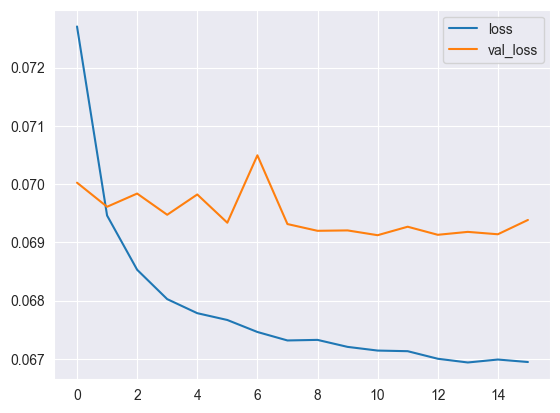

In [84]:
loss_df = pd.DataFrame(model.history.history)
loss_df.plot();

with "relu" activation function

In [85]:
model = Sequential()
model.add(LSTM(64, activation = 'relu', return_sequences=True, input_shape = (length, n_features)))
model.add(Dropout(0.2))  
model.add(LSTM(32, activation = 'relu', return_sequences=True))
model.add(Dropout(0.2))  
model.add(LSTM(16, activation = 'relu'))
model.add(Dropout(0.2)) 
model.add(Dense(1))
model.compile(optimizer = 'adam', loss = 'mse')

c:\Users\Shirin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [86]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 12, 64)         │        17,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 12, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 12, 32)         │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 32,977 (128.82 KB)

 Trainable params: 32,977 (128.82 KB)

 Non-trainable params: 0 (0.00 B)

In [87]:
early_stop = EarlyStopping(monitor = 'val_loss', patience = 5, restore_best_weights = True)

In [88]:
model.fit(generator,
            epochs = 20,
            validation_data = validation_generator,
            callbacks = [early_stop]);

Epoch 1/20
  25/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.1934  

c:\Users\Shirin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning:

Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.



1249/1249 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step - loss: 0.0833 - val_loss: 0.0706
Epoch 2/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.0685 - val_loss: 0.0698
Epoch 3/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - loss: 0.0676 - val_loss: 0.0699
Epoch 4/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - loss: 0.0684 - val_loss: 0.0697
Epoch 5/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0681 - val_loss: 0.0697
Epoch 6/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.0676 - val_loss: 0.0695
Epoch 7/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0675 - val_loss: 0.0703
Epoch 8/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.0668 - val_loss: 0.0695
Epoch 9/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0679 - val_loss: 0.0695
Epoch 10/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.0686 - val_loss: 0.0699
Epoch 11/20
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.0683 - val_loss: 0.0695
Epoch 12/20
1249/1249 ━━━━━━━━━━━━━

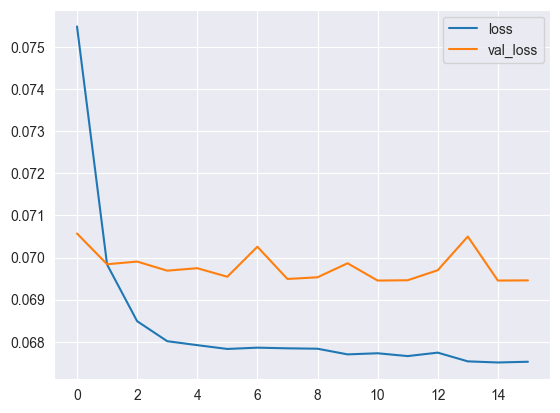

In [89]:
loss_df = pd.DataFrame(model.history.history)
loss_df.plot();

# GRU

In [90]:
from tensorflow.keras.layers import Dense, LSTM, Bidirectional, Dropout,GRU

In [91]:
train_scaled.shape

(1261, 3)

In [92]:
n_features = train_scaled.shape[1]

In [93]:
model = Sequential()
model.add(GRU(units=128, input_shape=(length, n_features)))  
model.add(Dense(units=1))
model.compile(optimizer='adam', loss='mse')

c:\Users\Shirin\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\rnn\rnn.py:204: UserWarning:

Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.



In [94]:
early_stop = EarlyStopping(monitor = 'val_loss', patience = 5, restore_best_weights = True)

In [95]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 128)            │        51,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,201 (200.00 KB)

 Trainable params: 51,201 (200.00 KB)

 Non-trainable params: 0 (0.00 B)

In [96]:
model.fit(generator, 
          epochs=30, 
          batch_size=32,
          validation_data=validation_generator,
          callbacks=[early_stop])

Epoch 1/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0726 - val_loss: 0.0700
Epoch 2/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0676 - val_loss: 0.0692
Epoch 3/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - loss: 0.0664 - val_loss: 0.0693
Epoch 4/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - loss: 0.0678 - val_loss: 0.0700
Epoch 5/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - loss: 0.0665 - val_loss: 0.0693
Epoch 6/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0674 - val_loss: 0.0693
Epoch 7/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0657 - val_loss: 0.0691
Epoch 8/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - loss: 0.0661 - val_loss: 0.0695
Epoch 9/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - loss: 0.0669 - val_loss: 0.0693
Epoch 10/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0689 - val_loss: 0.0691
Epoch 11/30
1249/1249 ━━━━━━━━━━━━━━━━━━━━ 10s 8ms/step - loss: 0.0673 - val_loss: 0.0697
Epoch 12/30
1249/1249 

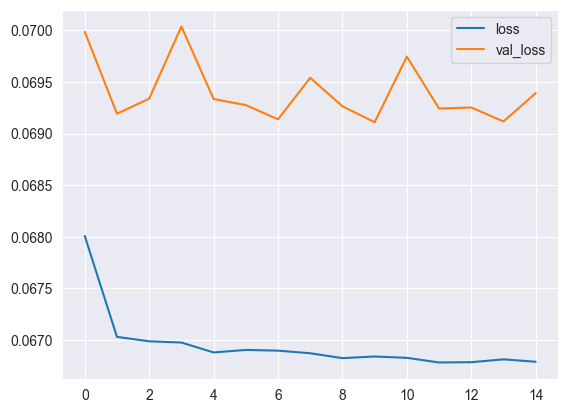

In [97]:
loss_df = pd.DataFrame(model.history.history)
loss_df.plot();